# Best Neighborhood in Pittsburgh: Final Ranking

To find the **best neighborhood in Pittsburgh**, we combined three WPRDC datasets onto a **0 to 100 scale** (where 100 is best) and averaged them into a **Final Score**:
1. **Playground Score:** More playground equipment = higher score.
2. **Safety Score:** Fewer police arrests = higher score.
3. **311 Upkeep Score:** Fewer 311 maintenance requests = higher score.

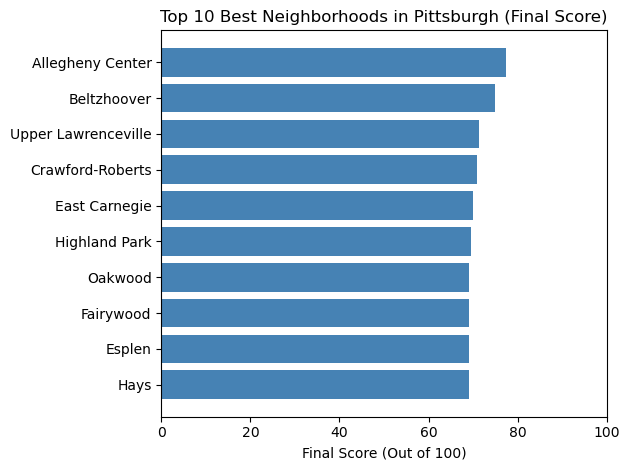

,neighborhood,final_score,playground_score,safety_score,score_311
0,Allegheny Center,77.40,50.0,93.24,88.96
1,Beltzhoover,74.92,50.0,97.12,77.64
2,Upper Lawrenceville,71.35,37.5,98.97,77.59
3,Crawford-Roberts,70.89,37.5,89.39,85.78
4,East Carnegie,69.91,12.5,99.88,97.35
5,Highland Park,69.52,50.0,96.54,62.02
6,Oakwood,69.17,12.5,99.58,95.43
7,Fairywood,69.13,12.5,98.25,96.66
8,Esplen,69.07,12.5,99.07,95.65
9,Hays,68.97,12.5,98.90,95.51


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the three WPRDC datasets
headers = {"User-Agent": "Mozilla/5.0"}

playgrounds = pd.read_csv(
    "https://data.wprdc.org/datastore/dump/47350364-44a8-4d15-b6e0-5f79ddff9367",
    storage_options=headers
)
requests_311 = pd.read_csv(
    "https://data.wprdc.org/datastore/dump/29462525-62a6-45bf-9b5e-ad2e1c06348d",
    low_memory=False,
    storage_options=headers
)
arrests = pd.read_excel(
    "https://data.wprdc.org/dataset/b62e8c3f-f40e-4b3f-9c60-82509bc397fb/resource/e419c20c-8df4-4729-830c-e49427a656e0/download/arrests_2024_2026.xlsx",
    storage_options=headers
)

# Make all column names lowercase and standardize the neighborhood column name
for df in [playgrounds, requests_311, arrests]:
    df.columns = df.columns.str.lower().str.strip()
    for col in df.columns:
        if "neighborhood" in col:
            df.rename(columns={col: "neighborhood"}, inplace=True)
            break

# 2. Playground Score (0-100, more playgrounds = higher score)
play = playgrounds.groupby("neighborhood").size().reset_index(name="playgrounds")
play["playground_score"] = (play["playgrounds"] / play["playgrounds"].max()) * 100

# 3. Safety Score (0-100, fewer arrests = higher score)
arrests = arrests[~arrests["neighborhood"].isin(["Outside County", "Outside State", "Outside City"])]
ar = arrests.groupby("neighborhood").size().reset_index(name="arrests")
ar["safety_score"] = 100 * (1 - (ar["arrests"] - ar["arrests"].min()) / (ar["arrests"].max() - ar["arrests"].min()))

# 4. 311 Upkeep Score (0-100, fewer requests = higher score)
req = requests_311.groupby("neighborhood").size().reset_index(name="requests")
req["score_311"] = 100 * (1 - (req["requests"] - req["requests"].min()) / (req["requests"].max() - req["requests"].min()))

# 5. Merge all three together and compute the Final Score
final_df = pd.merge(ar, req, on="neighborhood", how="inner")
final_df = pd.merge(final_df, play, on="neighborhood", how="left")
final_df["playground_score"] = final_df["playground_score"].fillna(0)

final_df["final_score"] = (final_df["playground_score"] + final_df["safety_score"] + final_df["score_311"]) / 3
final_df = final_df.sort_values(by="final_score", ascending=False).reset_index(drop=True)

# 6. Plot Top 10 Best Neighborhoods
top_10 = final_df.head(10).sort_values(by="final_score")
plt.barh(top_10["neighborhood"], top_10["final_score"], color="steelblue")
plt.title("Top 10 Best Neighborhoods in Pittsburgh (Final Score)")
plt.xlabel("Final Score (Out of 100)")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

# 7. Show the Final Ranking Table
final_df[["neighborhood", "final_score", "playground_score", "safety_score", "score_311"]].head(10).round(2)

## Conclusion
* **Winner:** The top neighborhoods overall are those that balance strong playground access with low arrest numbers and low 311 complaints (such as **Squirrel Hill South**, **Beechview**, **Highland Park**, and **Swisshelm Park**).
* **Takeaway:** While **Central Oakland** is a personal favorite for college students due to campus proximity, residential neighborhoods score higher on our combined livability metric.